# m6Brain clock quickstart

Predict the age of the samples of a public mouse proteome with the m6Brain clock, an elastic net of age on brain protein abundances guided by m6Brain, an m6A-aware model of brain proteome aging. The example is the whole-brain proteome of Scifo et al. 2025 (PXD058684): 45 mice aged 3 to 26 months, 4,714 proteins with gene symbols, log intensities, and a row `age` with the ages in months. The clock was not fitted on this cohort. Besides m6Brain the notebook needs `matplotlib` and `jupyter`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import m6brain as mb

table = pd.read_csv("data/scifo2025_whole_brain.csv")
table.iloc[:4, :5]

,symbol,c3662,c2295,c1358,c1364
0,Tuba1c,33.783,33.303,33.863,33.754
1,Tubb2a,33.988,33.432,33.879,33.563
2,Actg1,33.459,33.651,33.460,33.489
3,Mbp,32.997,32.822,32.937,33.356


Predict the age of every sample. The first column holds the gene symbols; the row `age` is used for the correlation and the age acceleration.

In [2]:
result = mb.predict_age(table, species="mouse")
print(result.attrs)
result.head()

{'species': 'mouse', 'ids': 'symbol', 'genes_matched': 190, 'genes_input': 4714, 'clock_genes': 279, 'unit': 'months', 'pearson_r': 0.811377265463883, 'pearson_p': 1.383704454134905e-11}


,sample,predicted_age,n_genes_matched,age,age_acceleration
0,c3662,15.000244,188,8.0,3.250041
1,c2295,9.870147,179,8.0,-1.880057
2,c1358,11.841994,185,8.0,0.091790
3,c1364,12.259120,182,8.0,0.508917
4,c1378,10.343207,182,8.0,-1.406996


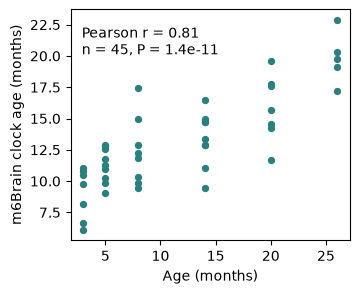

In [3]:
r, p = result.attrs["pearson_r"], result.attrs["pearson_p"]
fig, ax = plt.subplots(figsize=(3.6, 3))
ax.scatter(result.age, result.predicted_age, s=18, color="#2a7f7f")
ax.set(xlabel="Age (months)", ylabel="m6Brain clock age (months)")
ax.text(0.04, 0.93, f"Pearson r = {r:.2f}\nn = {len(result)}, P = {p:.1e}", transform=ax.transAxes, va="top")
plt.show()

The predicted ages are centred on the training mean age (the intercept of the clock), so the mean of a table is not an estimate of its age; the differences between samples are. `age_acceleration` is the residual of the predicted age on the chronological age in a linear fit over the samples (`controls=` fits it on the control samples only and applies it to all). The samples with the largest acceleration:

In [4]:
result.nlargest(3, "age_acceleration")

,sample,predicted_age,n_genes_matched,age,age_acceleration
6,c1383,17.474359,187,8.0,5.724155
18,c3775,22.870493,182,26.0,3.965568
0,c3662,15.000244,188,8.0,3.250041


The label-free mode `score` weights the proteins by the age z that m6Brain predicts from the transcript, with nothing fitted on ages; it is standardised within the table and not in years.

In [5]:
mb.score(table, species="mouse").attrs["pearson_r"]

0.7419635602248962

The proteins with the largest clock weights (age effect per SD of the protein, in months), and the weights of one gene: its clock weight, its label-free weight (`prediction`), the age z observed in the training cohorts and its number of m6A sites.

In [6]:
w = mb.weights("mouse").set_index("symbol")
clock = w[w.clock_weight != 0]
pd.concat([clock.nlargest(5, "clock_weight"), clock.nsmallest(5, "clock_weight")]).drop(columns="gene_id")

,clock_weight,prediction,observed_z,m6A_sites
symbol,,,,
Ppt1,1.493510,2.276949,16.839230,7
C4b,1.062026,4.368467,14.919033,0
Wdr7,0.394869,-2.328546,-2.544843,17
Mical1,0.384872,2.720969,6.513644,0
Ifit3,0.358022,2.973135,9.736253,3
Lgals9,-0.436742,2.631336,3.194917,0
Tnc,-0.431823,4.712032,-8.255273,1
Lipa,-0.257269,2.586468,5.216998,4
Pdpk1,-0.225248,-2.002230,-3.732783,8


In [7]:
mb.gene("Gfap", "mouse")

gene_id         ENSMUSG00000020932
symbol                        Gfap
clock_weight                   0.0
prediction                4.780748
observed_z                 9.98879
m6A_sites                        6
Name: 1878, dtype: object

The same call works on a file (`mb.predict_age("proteome.csv", "mouse")`), and `m6brain age proteome.csv --species mouse` on the command line. Weights version:

In [8]:
mb.weights_version()

{'date': '2026-10-23',
 'git_commit': 'ca8d256f',
 'mouse': {'genes': 10606,
  'clock_genes': 279,
  'intercept': 13.216479740883866,
  'unit': 'months',
  'weights_computed': '2026-10-23',
  'sha256': '8094707075d5d9f2'},
 'human': {'genes': 9990,
  'clock_genes': 421,
  'intercept': 69.36827251358973,
  'unit': 'years',
  'weights_computed': '2026-10-23',
  'sha256': '3d888834481f2816'}}